In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy

a, b = -0.1, 0.4
n_max = 60

## Setup
Wir definieren eine 1D-Funktion $f$, und nehmen an, dass wir deren Ableitung kennen (symbolisch mit sympy). 

Falls die Ableitung $df$ unbekannt ist, können wir diese auch annähern (Differenzenquotient, Richardson, ...)

In [3]:
t = sy.symbols(("t"))
f_exp = sy.cos(2 * sy.pi * t + 0.5) * 2000
df_exp = sy.diff(f_exp)
f = sy.lambdify(t, f_exp, "numpy")
df = sy.lambdify(t, df_exp, "numpy")

## Newton-Verfahren
Unsere erste Annäherung für eine nullstelle ist `start` $=x_0$. Wir berechnen rekursiv $x_{i+1}$ aus $x_i$, und brechen ab, wenn wir bei $f(x_k)=10^{-14}$ ankommen, was uns nahe genug an einer Nullstelle ist. 

In [4]:
start = 0
atol = 1e-14

Zur berechnung von $x_{i+1}$ benötigen wir die Tangentensteigung $m$ und Funktionswert $y$ an der Stützstelle $x_i$. Der erste Teil der Schleife stellt die rekursive Berechnung dar. 

In [ ]:
x = [start]
S = []
n = 0

for i in range(n_max):
    # Berechne das neue x und füge es der Liste hinzu
    n += 1
    x_i = x[-1]
    y = f(x_i)
    m = df(x_i)
    x.append(x[-1] - y/m)

    # Tangente, nur für den Plot
    def s(z, m=m, y=y, x_i=x_i):
        return (z - x_i) * m + y
    S.append(s)

    # Abbrechen, wenn wir genug nahe sind! 
    if (np.abs(f(x[-1])) < atol):
        break

x = np.array(x)

## Plots
Der folgende Plot zeigt die ersten `prt_n` Tangenten, deren Nullstellen und Funktionswerte an diesen Stellen: 

f(0.17042252845405234) = 1.2246467991473532e-13


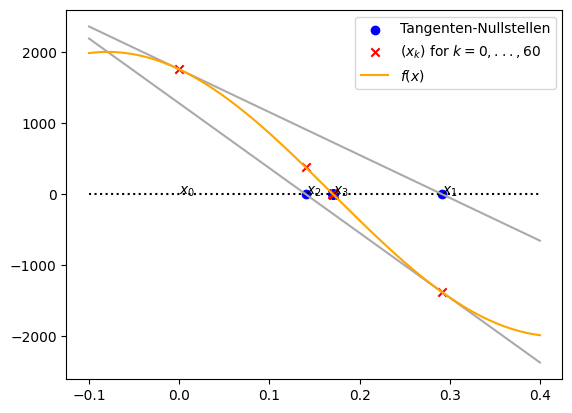

In [13]:
## Styling für den Plot
N = 500
X = np.linspace(a, b, N)
prt_n = 2

plt.plot((a, b), (0, 0), linestyle=":", color="black")
plt.scatter(x[1:], np.zeros_like(x[1:]), label="Tangenten-Nullstellen", color="blue")
plt.scatter(x, f(x), color="red", marker="x", label=r"$(x_k)$ for $k=0,...,{}$".format(n))

for i in range(prt_n):
    plt.plot(X, S[i](X), color="#aaa") #, label=r"$T_%d(x)$" % n)

plt.plot(X, f(X), label=r"$f(x)$", color="orange")
for i in range(prt_n+2):
    plt.annotate(r"$x_%s$" % i, (x[i], 0))
plt.legend()

print(f"f({x[-1]}) = {f(x[-1])}")

Für eine animierte Darstellung des newton-Verfahrens, führt den folgenden code aus. Passt `step_time` an, um die geschwindigkeit anzupassen. 
`max_step` beschreibt, wie viele Schritte maximal angezeigt werden. 

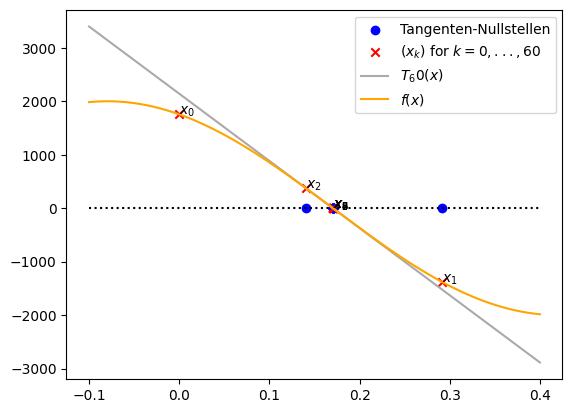

f(0.17042252845405234) = 1.2246467991473532e-13


In [35]:
import IPython
import time
step_time = 2
max_step = 10

for i in range(min(n-2, max_step)):
    IPython.display.clear_output(True)

    plt.plot((a, b), (0, 0), linestyle=":", color="black")
    plt.scatter(x[1:i+1], np.zeros_like(x[1:i+1]), label="Tangenten-Nullstellen", color="blue")
    plt.scatter(x[:i+1], f(x[:i+1]), color="red", marker="x", label=r"$(x_k)$ for $k=0,...,{}$".format(n))
    if i > 0:
        plt.plot(X, S[i-1](X), color="#aaa", label=r"$T_%d(x)$" % n)
    for j in range(i+1):
        plt.annotate(r"$x_%s$" % j, (x[j], f(x[j])))
    plt.plot(X, f(X), label=r"$f(x)$", color="orange")
    plt.legend()
    plt.show()

    print(f"f({x[-1]}) = {f(x[-1])}")
    time.sleep(step_time)
